In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
df = pd.read_csv('drive/MyDrive/Advertising.csv')
df

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5


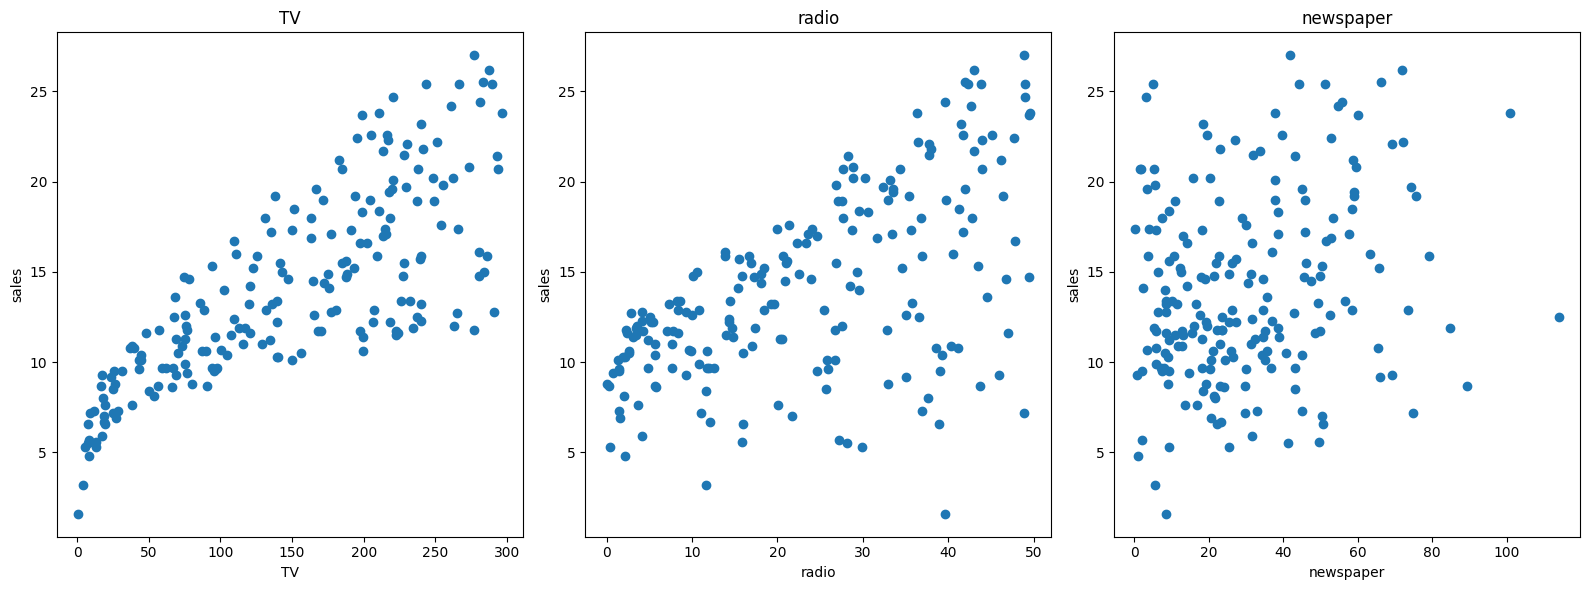

In [ ]:
fig, axes = plt.subplots( ncols = 3,nrows=1, figsize=(16,6))

axes[0].plot(df['TV'], df['sales'], 'o')
axes[1].plot(df['radio'], df['sales'], 'o')
axes[2].plot(df['newspaper'], df['sales'], 'o')
axes[0].set_xlabel('TV')
axes[1].set_xlabel('radio')
axes[2].set_xlabel('newspaper')
axes[0].set_ylabel('sales')
axes[1].set_ylabel('sales')
axes[2].set_ylabel('sales')
axes[0].set_title('TV')
axes[1].set_title('radio')
axes[2].set_title('newspaper')
plt.tight_layout()
plt.show()

In [ ]:
X= df.drop('sales',axis=1)
y=df['sales']

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
lin = LinearRegression()
lin.fit(X_train,y_train)

LinearRegression()

In [ ]:
pd.DataFrame({'Tv':[37.8],'radio':[69.2],'newspaper':[22.1]})

,Tv,radio,newspaper
0,37.8,69.2,22.1


In [ ]:
lin.predict(pd.DataFrame({'TV':[230.1],'radio':[37.8],'newspaper':[69.2]}))


array([20.50372383])

In [ ]:
lin.score(X_train,y_train)
lin.predict(df.drop('sales',axis=1).head(1))

array([20.50372383])

In [ ]:
lin.score(X_test,y_test)

0.9185780903322445

In [ ]:
test_predictions = lin.predict(X_test)
test_predictions


array([15.74131332, 19.61062568, 11.44888935, 17.00819787,  9.17285676,
        7.01248287, 20.28992463, 17.29953992,  9.77584467, 19.22194224,
       12.40503154, 13.89234998, 13.72541098, 21.28794031, 18.42456638,
        9.98198406, 15.55228966,  7.68913693,  7.55614992, 20.40311209,
        7.79215204, 18.24214098, 24.68631904, 22.82199068,  7.97962085,
       12.65207264, 21.46925937,  8.05228573, 12.42315981, 12.50719678,
       10.77757812, 19.24460093, 10.070269  ,  6.70779999, 17.31492147,
        7.76764327,  9.25393336,  8.27834697, 10.58105585, 10.63591128,
       13.01002595,  9.77192057, 10.21469861,  8.04572042, 11.5671075 ,
       10.08368001,  8.99806574, 16.25388914, 13.23942315, 20.81493419,
       12.49727439, 13.96615898, 17.56285075, 11.14537013, 12.56261468,
        5.50870279, 23.29465134, 12.62409688, 18.77399978, 15.18785675])

In [ ]:
mae=(y_test-test_predictions).sum()*-1


In [ ]:
((y_test-test_predictions)**2).sum()**(1/2)

np.float64(11.744062409285076)

In [ ]:
test_residuals=y_test-test_predictions
((test_residuals**2).sum()/(test_residuals.count()))**(1/2)

np.float64(1.5161519375993884)

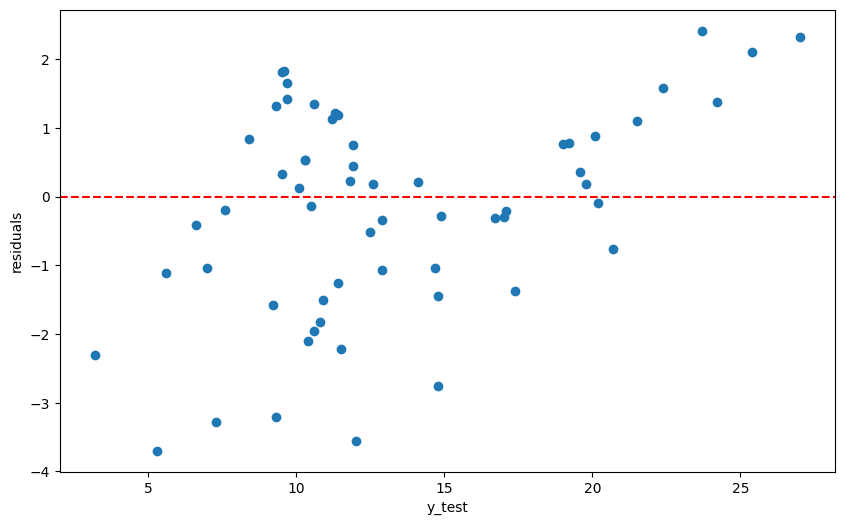

In [ ]:
plt.figure(figsize=(10,6))
plt.scatter(y_test,test_residuals)
plt.axhline(y=0,color='r',ls='--')
plt.xlabel('y_test')
plt.ylabel('residuals')
plt.show()


In [ ]:
from sklearn.preprocessing import PolynomialFeatures

In [ ]:
poly = PolynomialFeatures(degree=2,include_bias=False)
newX=pd.DataFrame(poly.fit_transform(X))




In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(newX, y, test_size=0.3, random_state=101)

In [ ]:
from sklearn.linear_model import LinearRegression
lin = LinearRegression()
lin.fit(X_train,y_train)

LinearRegression()

In [ ]:
lin.score(X_test,y_test)

0.9843529333146783

In [ ]:
lin.coef_

array([ 5.17095811e-02,  1.30848864e-02,  1.20000085e-02, -1.10892474e-04,
        1.14212673e-03, -5.24100082e-05,  3.34919737e-05,  1.46380310e-04,
       -3.04715806e-05])

In [ ]:
y_test_predict=lin.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
MAE=mean_absolute_error(y_test,y_test_predict)
MSE=mean_squared_error(y_test,y_test_predict)
RMSE=np.sqrt(MSE)

In [ ]:
MAE, MSE, RMSE

(0.4896798044803838, 0.4417505510403753, np.float64(0.6646431757269274))

In [ ]:
rmse_for_test=[]
rmse_for_train=[]
mae_for_test=[]
mae_for_train=[]
for d in range(1,10):
  poly=PolynomialFeatures(degree=d,include_bias=False)
  newX=poly.fit_transform(X)

  X_train, X_test, y_train, y_test = train_test_split(newX, y, test_size=0.3, random_state=101)

  lin=LinearRegression()
  lin.fit(X_train,y_train)

  rmse_for_train.append(np.sqrt(mean_squared_error(y_train,lin.predict(X_train))))
  rmse_for_test.append(np.sqrt(mean_squared_error(y_test,lin.predict(X_test))))
  mae_for_train.append(mean_absolute_error(y_train,lin.predict(X_train)))
  mae_for_test.append(mean_absolute_error(y_test,lin.predict(X_test)))





In [ ]:
rmse_for_train

[np.float64(1.734594124329376),
 np.float64(0.5879574085292232),
 np.float64(0.43393443569020673),
 np.float64(0.35170836883993495),
 np.float64(0.25093430399765837),
 np.float64(0.20953728599482707),
 np.float64(0.22046859152326304),
 np.float64(0.27149790271647406),
 np.float64(0.5132042855932262)]

In [ ]:
rmse_for_test

[np.float64(1.5161519375993877),
 np.float64(0.6646431757269274),
 np.float64(0.5803286825236476),
 np.float64(0.5077742639859423),
 np.float64(2.575825081302852),
 np.float64(9.871410116034689),
 np.float64(41.330566088617964),
 np.float64(3103.1690816455084),
 np.float64(12768.354850329179)]

[0, 10, 0, 2000]

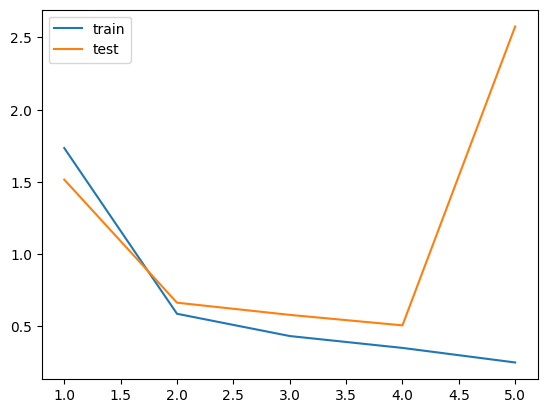

In [ ]:
plt.plot(range(1,6),rmse_for_train[:5],label='train')
plt.plot(range(1,6),rmse_for_test[:5],label='test')
plt.legend()
plt.axes

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
poly=PolynomialFeatures(degree=2,include_bias=False)
newX=poly.fit_transform(X)